In [22]:
import sys
import os
import json
import numpy as np
import scipy as sp

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../mouse-control/src'))
from utils_mouse_control import read_utils as read_utils_control

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

from utils import ai_slob

In [23]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

<module 'utils.analysis_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/analysis_utils.py'>

In [3]:
organism = 'mouse'

ll = 'll00'
data_variant = 'gcamp'
model_variant = 'ns'
manual = False
full = False

save = False

In [4]:
# file_ids = list(range(0, 8+1))
file_ids = [2]

In [5]:
filenames = analysis_utils.read_filenames(organism, file_ids)

model_path = read_utils.get_model_path()

metadata = (filenames, model_path, model_variant, data_variant, manual, full)

In [6]:
((boms_spn, _, _, _, _, _, _),
 (hgms_spn, _, _, _, _, _, _)) = analysis_utils.read_predictionss(*metadata)

In [7]:
neuron_scores = analysis_utils.assemble_scores(boms_spn, hgms_spn)

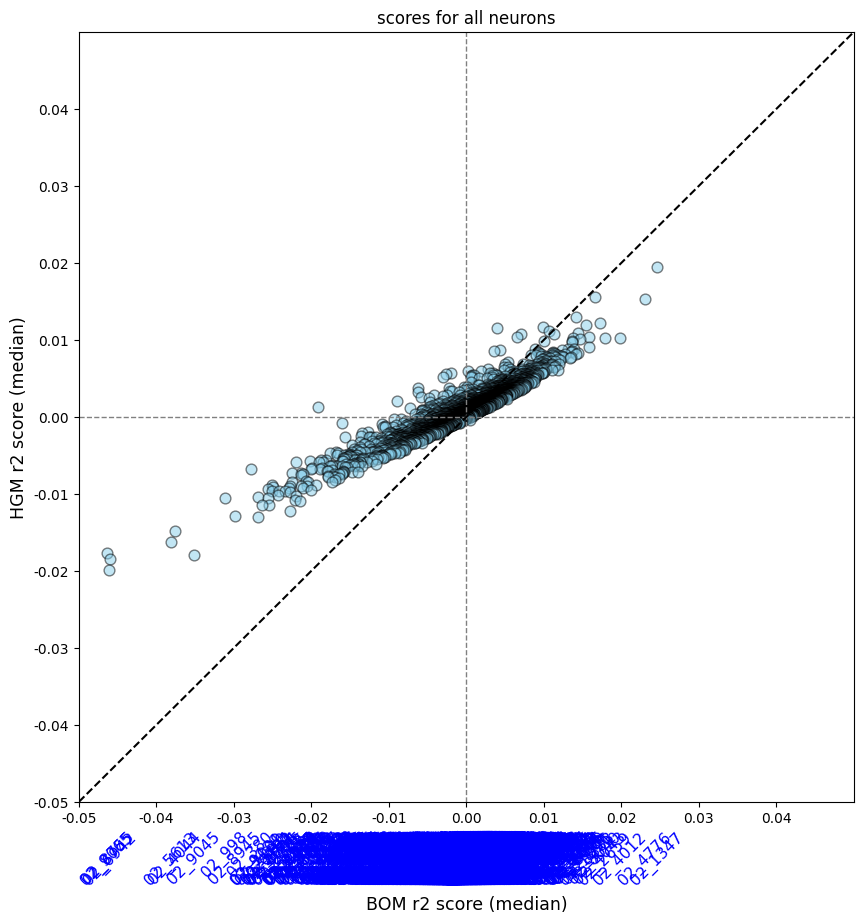

In [11]:
plot_utils.plot_performance_plot(
	neuron_scores, None,
	title='scores for all neurons', limits=(-0.05, 0.05, -0.05, 0.05), force_medians=False, horizontal_bps=False,
	save_path=f'../../out/plots/scores/{model_variant}_scores_all' if save else None
)

# shuffle control

In [12]:
shuffle_scores = list()
for shuffle_id in range(100):
	((boms_spn, _, _, _, _, _, _),
	 (hgms_spn, _, _, _, _, _, _)) = analysis_utils.read_scoress(filenames, read_utils_control.get_model_path(shuffle_id), model_variant, data_variant, manual, full)
	shuffle_scores.append((boms_spn, hgms_spn))
neuron_scores_shuffle = [analysis_utils.assemble_scores(*shuffle_scores[i]) for i in range(100)]
shuffle_scores = None  # clear memory
neuron_scores_shuffle_merged = ai_slob.merge_neuron_scores_per_shuffle(neuron_scores_shuffle)

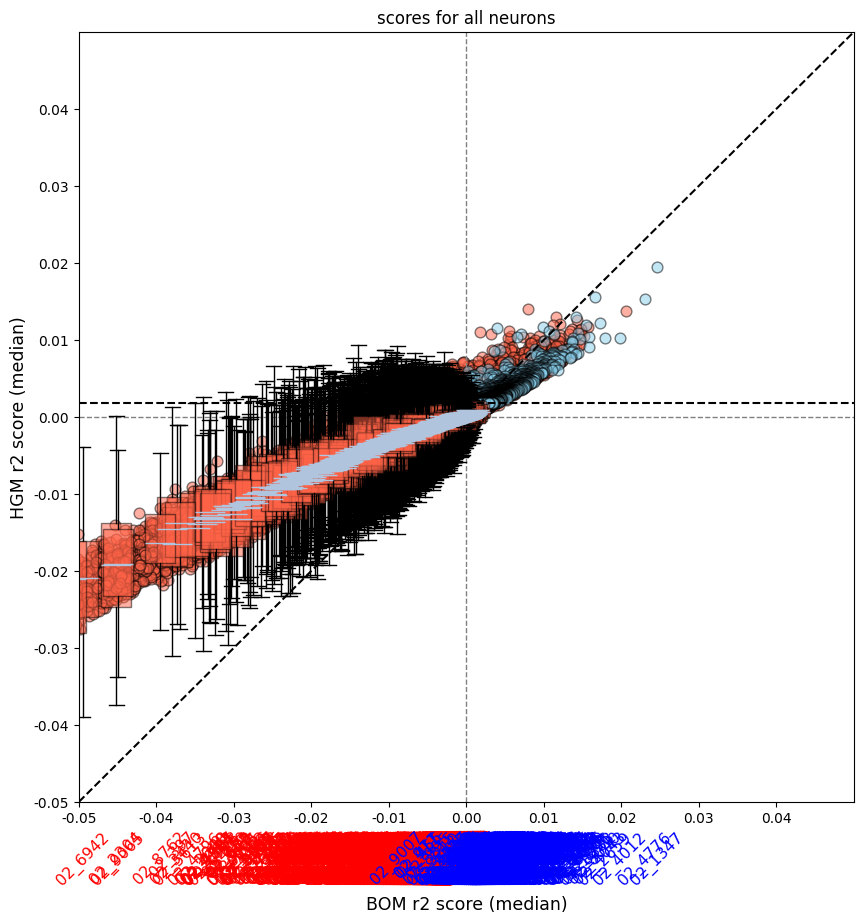

In [13]:
plot_utils.plot_performance_plot(
	neuron_scores, neuron_scores_shuffle_merged,
	title='scores for all neurons', limits=(-0.05, 0.05, -0.05, 0.05), force_medians=False, horizontal_bps=False,
)

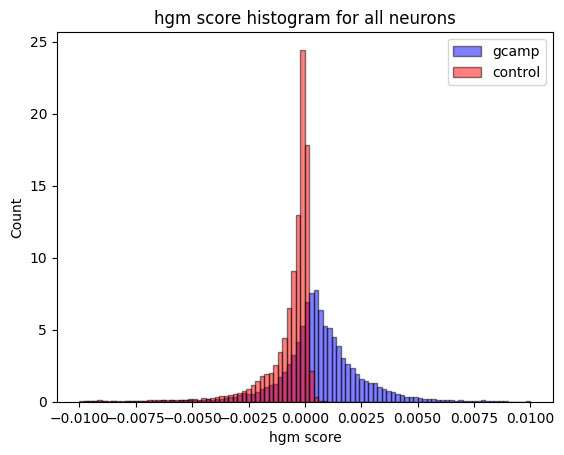

In [39]:
plot_utils.plot_performance_histogram(neuron_scores,
									  neuron_scores_shuffle_merged,
									  bins=100, range=(-0.01, 0.01),
									  title='hgm score histogram for all neurons')

In [24]:
# compute HGM percentiles (default agg: mean of flattened array)
percentiles_hgm = ai_slob.compute_neuron_percentiles(
    neuron_scores,
    neuron_scores_shuffle,
    model='hgm'
)

# compute BOM percentiles
percentiles_bom = ai_slob.compute_neuron_percentiles(
    neuron_scores,
    neuron_scores_shuffle,
    model='bom'
)

# print top 10 ID'd neurons by HGM percentile
top10 = list(percentiles_hgm.items())[:]
for label, pct in top10:
	print(f"{label}: {pct:.1f} percentile")

02_393: 100.0 percentile
02_1347: 100.0 percentile
02_8040: 100.0 percentile
02_4776: 100.0 percentile
02_2844: 100.0 percentile
02_4043: 100.0 percentile
02_1896: 100.0 percentile
02_3712: 100.0 percentile
02_1364: 100.0 percentile
02_2566: 100.0 percentile
02_2856: 100.0 percentile
02_1348: 100.0 percentile
02_2314: 100.0 percentile
02_048: 100.0 percentile
02_8883: 100.0 percentile
02_2659: 100.0 percentile
02_6242: 100.0 percentile
02_4012: 100.0 percentile
02_5000: 100.0 percentile
02_9082: 100.0 percentile
02_9037: 100.0 percentile
02_4028: 100.0 percentile
02_041: 100.0 percentile
02_8032: 99.0 percentile
02_9242: 100.0 percentile
02_5277: 100.0 percentile
02_1337: 100.0 percentile
02_7287: 100.0 percentile
02_5249: 100.0 percentile
02_034: 100.0 percentile
02_9235: 100.0 percentile
02_5768: 99.0 percentile
02_006: 99.0 percentile
02_7792: 100.0 percentile
02_3845: 100.0 percentile
02_7854: 98.0 percentile
02_6635: 100.0 percentile
02_5464: 100.0 percentile
02_100: 100.0 percent

In [32]:
# Build sorted list + OrderedDict
entries_sorted, percentiles_hgm_best = ai_slob.build_sorted_percentiles(percentiles_hgm, neuron_scores, model_index=1)

# entries_sorted is a list of tuples: (label, percentile, actual_hgm)
# percentiles_hgm_best is an OrderedDict: label -> (percentile, actual_hgm)
percentiles_hgm_best = {key: val for key, val in percentiles_hgm_best.items() if val[0] == 100}

# Quick check: print top 10
print("Top 10 by percentile (tie-breaker = actual HGM):")
for label, pct, actual in entries_sorted[:50]:
	print(f"{label}: {pct:.2f} percentile, actual_hgm = {actual:.4g}")

Top 10 by percentile (tie-breaker = actual HGM):
02_393: 100.00 percentile, actual_hgm = 0.03817
02_1347: 100.00 percentile, actual_hgm = 0.01952
02_8040: 100.00 percentile, actual_hgm = 0.01558
02_4776: 100.00 percentile, actual_hgm = 0.01531
02_2844: 100.00 percentile, actual_hgm = 0.01294
02_4043: 100.00 percentile, actual_hgm = 0.01221
02_1896: 100.00 percentile, actual_hgm = 0.01194
02_3712: 100.00 percentile, actual_hgm = 0.01161
02_1364: 100.00 percentile, actual_hgm = 0.01152
02_2566: 100.00 percentile, actual_hgm = 0.0112
02_2856: 100.00 percentile, actual_hgm = 0.01092
02_1348: 100.00 percentile, actual_hgm = 0.0108
02_2314: 100.00 percentile, actual_hgm = 0.01079
02_048: 100.00 percentile, actual_hgm = 0.0104
02_8883: 100.00 percentile, actual_hgm = 0.01033
02_2659: 100.00 percentile, actual_hgm = 0.01028
02_6242: 100.00 percentile, actual_hgm = 0.01027
02_4012: 100.00 percentile, actual_hgm = 0.01025
02_5000: 100.00 percentile, actual_hgm = 0.01011
02_9082: 100.00 percentil

In [35]:
print('Neuron names for copying:')
print(', '.join([f'\'{label}\'' for label in percentiles_hgm_best]))

Neuron names for copying:
'02_393', '02_1347', '02_8040', '02_4776', '02_2844', '02_4043', '02_1896', '02_3712', '02_1364', '02_2566', '02_2856', '02_1348', '02_2314', '02_048', '02_8883', '02_2659', '02_6242', '02_4012', '02_5000', '02_9082', '02_9037', '02_4028', '02_041', '02_9242', '02_5277', '02_1337', '02_7287', '02_5249', '02_034', '02_9235', '02_7792', '02_3845', '02_6635', '02_5464', '02_100', '02_2005', '02_2217', '02_9107', '02_044', '02_4039', '02_356', '02_4019', '02_4035', '02_5262', '02_071', '02_9053', '02_5400', '02_6795', '02_335', '02_4739', '02_981', '02_4121', '02_2854', '02_216', '02_7581', '02_9014', '02_9022', '02_3754', '02_7639', '02_1388', '02_4985', '02_313', '02_113', '02_987', '02_7350', '02_1001', '02_1922', '02_992', '02_5935', '02_3997', '02_8038', '02_6327', '02_8219', '02_754', '02_1545', '02_8338', '02_4885', '02_369', '02_6590', '02_9255', '02_4525', '02_1659', '02_2374', '02_3195', '02_008', '02_4353', '02_3740', '02_4775', '02_8346', '02_037', '02

In [26]:
importlib.reload(ai_slob)

<module 'utils.ai_slob' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/ai_slob.py'>

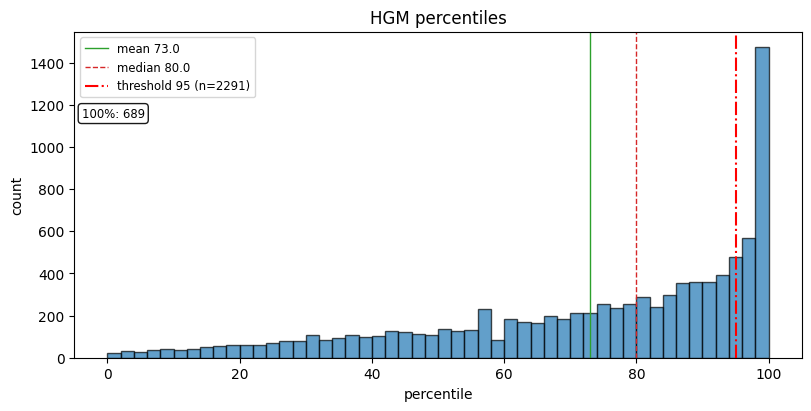

(array([  21.,   31.,   26.,   37.,   40.,   36.,   40.,   52.,   54.,
          58.,   61.,   60.,   68.,   77.,   77.,  106.,   84.,   93.,
         107.,   99.,  104.,  127.,  123.,  112.,  108.,  137.,  129.,
         133.,  233.,   84.,  183.,  170.,  165.,  197.,  185.,  210.,
         210.,  255.,  237.,  255.,  287.,  240.,  297.,  355.,  357.,
         358.,  392.,  480.,  569., 1473.]),
 array([  0.,   2.,   4.,   6.,   8.,  10.,  12.,  14.,  16.,  18.,  20.,
         22.,  24.,  26.,  28.,  30.,  32.,  34.,  36.,  38.,  40.,  42.,
         44.,  46.,  48.,  50.,  52.,  54.,  56.,  58.,  60.,  62.,  64.,
         66.,  68.,  70.,  72.,  74.,  76.,  78.,  80.,  82.,  84.,  86.,
         88.,  90.,  92.,  94.,  96.,  98., 100.]))

In [20]:
ai_slob.plot_percentile_hist(percentiles_hgm, bins=50, title='HGM percentiles', threshold=95)

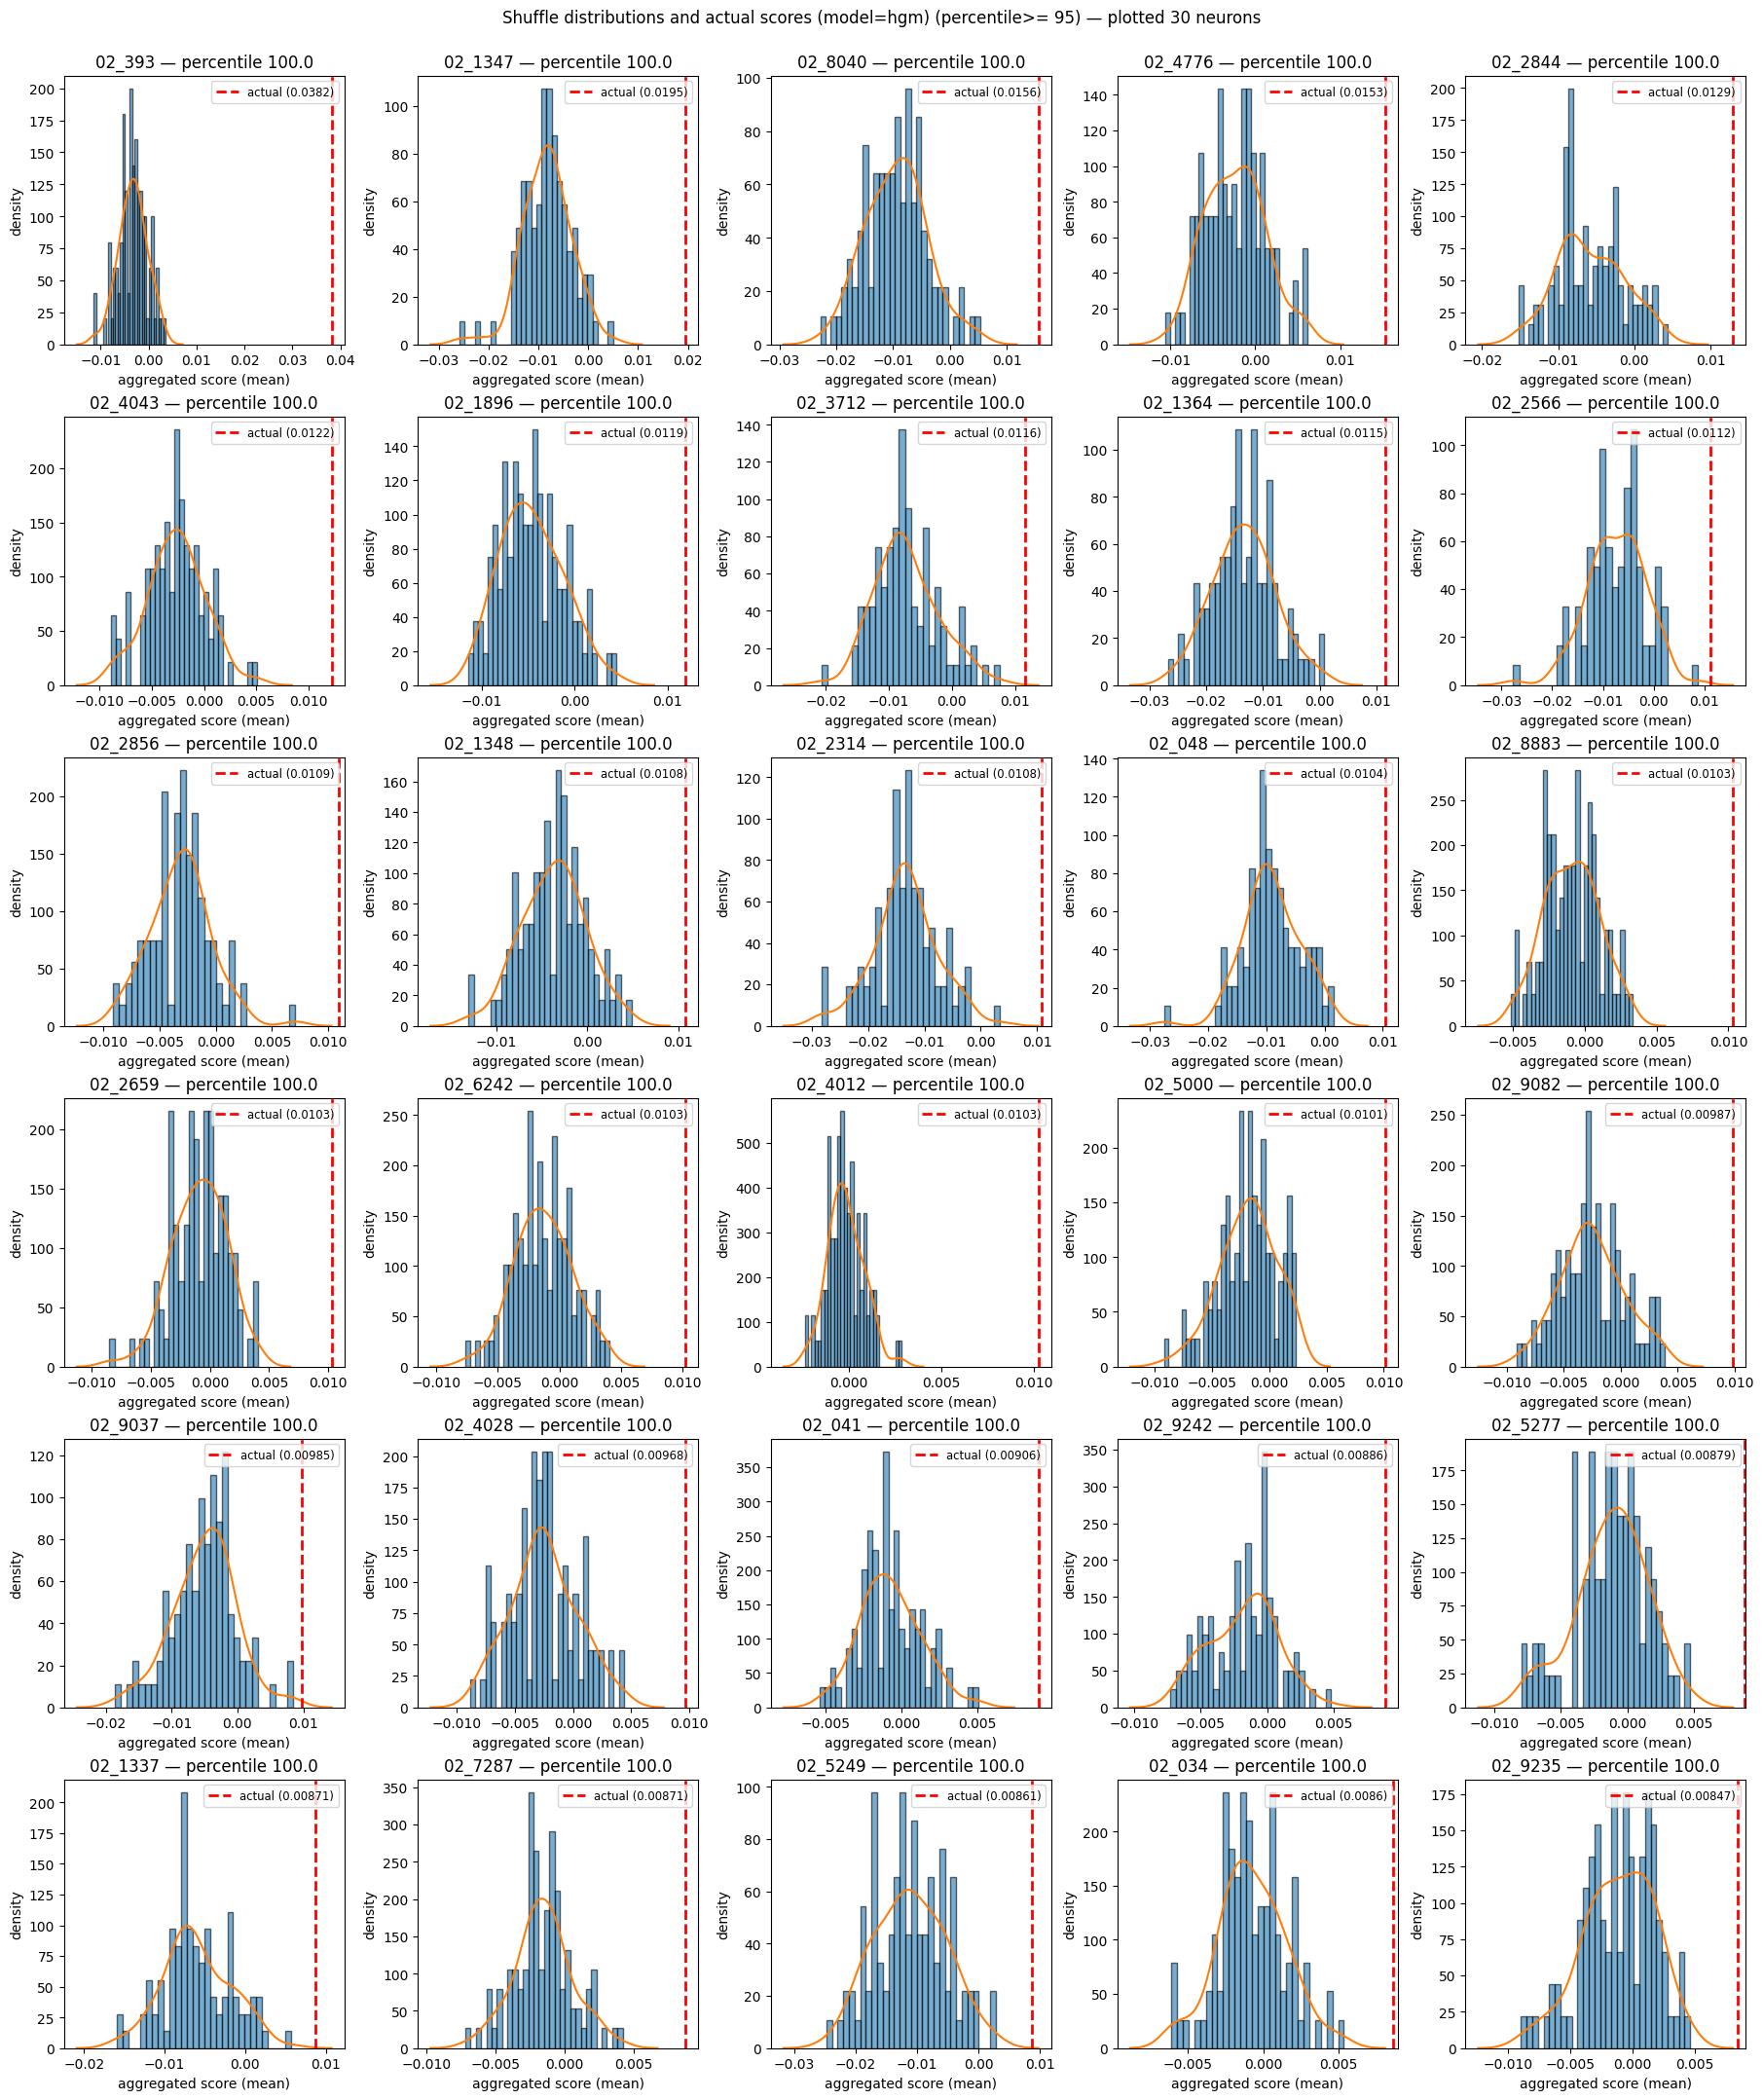

Plotted neurons: None


In [34]:
# Example usage: plots the top-10 neurons by actual HGM score
chosen = ai_slob.plot_first_n_neurons(neuron_scores, neuron_scores_shuffle, model='hgm', n=30, neuron_labels=percentiles_hgm_best.keys())
print("Plotted neurons:", chosen)

# If you want the literal insertion-order 'first 10 keys' instead, call:
# first10_insertion_order = list(neuron_scores.keys())[:10]
# chosen = plot_first_n_neurons(neuron_scores, neuron_scores_shuffle, model='hgm', neuron_labels=first10_insertion_order)